# NLP Lab 10 — Introduction to Machine Translation
**Maan Ghamdi | Student ID: 2240001433**

I explain the model layers, reproduce the introductory example, and train an English-to-French LSTM model using a reproducible sample of the assigned dataset. All displayed numerical results are produced by running the code.

## Running my notebook
I use **Python 3.12** with a standard Python 3 kernel. I run all cells from top to bottom. The first cell installs missing dependencies; this requires internet only for package installation. My dataset sample is embedded, so I do not need a Kaggle account or extra data files. Training runs on CPU. I use a small sample for a practical lab runtime, not a production translator.

In [1]:
import os, sys, subprocess, importlib.util
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
requirements = {
    'tensorflow': 'tensorflow==2.20.0', 'numpy': 'numpy==2.2.6',
    'pandas': 'pandas==2.3.3', 'sklearn': 'scikit-learn==1.7.2',
    'matplotlib': 'matplotlib==3.10.7', 'nltk': 'nltk==3.9.2',
}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from IPython.display import display
SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print('Python:', sys.version.split()[0], '| TensorFlow:', tf.__version__)
print('Dependencies ready; random seed:', SEED)

Python: 3.12.10 | TensorFlow: 2.20.0
Dependencies ready; random seed: 42


# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

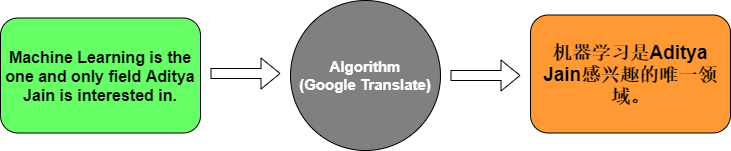

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural machine translation
I convert source words to embeddings, encode them with an LSTM, repeat the encoded vector over the target length, and decode it into French word probabilities.

`English IDs → Embedding → Encoder LSTM → RepeatVector → Decoder LSTM → Dense + softmax`

### Introductory three-pair example
I preserve the lab's small demonstration. It is too small for a meaningful generalization estimate: two pairs are used for training and one for testing. I therefore do not split those two training pairs again for validation.

In [2]:
english_sentences = ['Hello.', 'How are you?', 'This is a machine translation example.']
french_sentences = ['Bonjour.', 'Comment ça va?', 'Ceci est un exemple de traduction automatique.']
tokenizer_eng = Tokenizer(oov_token='<unk>')
tokenizer_frn = Tokenizer(oov_token='<unk>')
tokenizer_eng.fit_on_texts(english_sentences)
tokenizer_frn.fit_on_texts(french_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)
eng_word_index = tokenizer_eng.word_index
frn_word_index = tokenizer_frn.word_index
eng_padded = pad_sequences(eng_sequences, padding='post')
frn_padded = pad_sequences(frn_sequences, padding='post')
print('English sequences:', eng_sequences)
print('English vocabulary:', eng_word_index)
print('French sequences:', frn_sequences)
print('French vocabulary:', frn_word_index)
print('Padded English:\n', eng_padded)
print('Padded French:\n', frn_padded)

English sequences: [[2], [3, 4, 5], [6, 7, 8, 9, 10, 11]]
English vocabulary: {'<unk>': 1, 'hello': 2, 'how': 3, 'are': 4, 'you': 5, 'this': 6, 'is': 7, 'a': 8, 'machine': 9, 'translation': 10, 'example': 11}
French sequences: [[2], [3, 4, 5], [6, 7, 8, 9, 10, 11, 12]]
French vocabulary: {'<unk>': 1, 'bonjour': 2, 'comment': 3, 'ça': 4, 'va': 5, 'ceci': 6, 'est': 7, 'un': 8, 'exemple': 9, 'de': 10, 'traduction': 11, 'automatique': 12}
Padded English:
 [[ 2  0  0  0  0  0]
 [ 3  4  5  0  0  0]
 [ 6  7  8  9 10 11]]
Padded French:
 [[ 2  0  0  0  0  0  0]
 [ 3  4  5  0  0  0  0]
 [ 6  7  8  9 10 11 12]]


In [3]:
def make_model(source_vocab, target_vocab, source_length, target_length, units=64):
    network = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(source_length,), dtype='int32'),
        tf.keras.layers.Embedding(source_vocab, 64, mask_zero=True),
        tf.keras.layers.LSTM(units),
        tf.keras.layers.RepeatVector(target_length),
        tf.keras.layers.LSTM(units, return_sequences=True),
        tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(target_vocab, activation='softmax')),
    ])
    network.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
                    weighted_metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='token_accuracy')])
    return network

def dataset(x, y, batch_size=64, training=False):
    # Zero weights exclude target padding from loss and weighted accuracy.
    weights = (y != 0).astype('float32')
    ds = tf.data.Dataset.from_tensor_slices((x, y, weights))
    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.batch(batch_size).with_options(options)

eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=SEED)
model = make_model(len(eng_word_index)+1, len(frn_word_index)+1,
                   eng_padded.shape[1], frn_padded.shape[1])
model.fit(dataset(eng_train, frn_train, 1, True), epochs=50, shuffle=False, verbose=0)
print('Toy-example test results:', model.evaluate(dataset(eng_test, frn_test), verbose=0, return_dict=True))

def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded = pad_sequences(sequence, maxlen=model.input_shape[1], padding='post', truncating='post')
    ids = np.argmax(model(padded, training=False).numpy(), axis=-1)
    return frn_tokenizer.sequences_to_texts(ids)[0]

print('Input: How are you?')
print('Model translation:', translate_sentence('How are you?', model, tokenizer_eng, tokenizer_frn))

Toy-example test results: {'loss': 0.38415130972862244, 'token_accuracy': 0.0}
Input: How are you?
Model translation: va va va va va va va


## Task 1 — Understanding the model layers

1. **Embedding:** I use this layer to turn a word's integer ID into a trainable vector of real numbers. The ID is only a lookup key; the vector can learn useful relationships during training.
2. **Encoder LSTM:** I use the encoder to read the English sequence in order and summarize it in a fixed-length vector. Its memory helps it retain information from earlier words.
3. **Decoder LSTM:** I use the decoder to turn the repeated source representation into a sequence of hidden states, one for each French output position. The final dense layer then predicts the word at each position. This lab's decoder uses the repeated context, rather than feeding previous predicted words back into itself.
4. **Softmax:** I use softmax to convert output scores into a probability distribution over the French vocabulary at each position. Its probabilities sum to one, so I can choose the most likely word with `argmax` and train with categorical cross-entropy.

## Task 2 — English-to-French translation for e-commerce

I implement the same encoder/decoder architecture on the assigned [Kaggle English–French dataset](https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench), published by Devicharith.

The downloaded CSV contains **175,621 rows**. I remove missing values, lowercase text, normalize whitespace and Unicode punctuation, retain pairs with 2–7 English words and 2–9 French words, and keep one translation per normalized English sentence before sampling **4,000 pairs** with seed 42. This keeps repeated English sources out of different splits. The sample is compressed inside this notebook for independent reruns; it is real dataset text, not generated examples.

I split the sample into 80% training, 10% validation, and 10% test data. I fit vocabularies on the training set only. I reserve zero for padding, include an unknown token, and add an end token to French targets. I exclude padding from loss and accuracy. I select weights using validation loss and evaluate the test set only after training.

In [4]:
import base64, zlib, json, hashlib, re, unicodedata
SAMPLE_B64 = '...'
sample_bytes = zlib.decompress(base64.b64decode(SAMPLE_B64))
assert hashlib.sha256(sample_bytes).hexdigest() == 'c631af8ed66b07ed143f0afe39172da8dcf41f90bd00b65d225a52450312db82'
pairs = pd.DataFrame(json.loads(sample_bytes))
assert len(pairs) == 4000 and pairs.english.is_unique and not pairs.isna().any().any()
print('Embedded dataset sample:', pairs.shape)
display(pairs.head(8))

Embedded dataset sample: (4000, 2)


,english,french
0,crime is on the increase.,les crimes sont en augmentation.
1,set tom free.,libère tom.
2,you're not bruised.,tu n'es pas contusionné.
3,she was surprised at his appearance.,elle fut surprise par son apparition.
4,i don't have the money.,je ne dispose pas de l'argent.
5,"here, take this.","voilà, prends ceci !"
6,you alone can help me.,toi seul peut m'aider.
7,why don't you ask your boyfriend?,pourquoi ne demandes-tu pas à ton petit ami ?


In [5]:
train_pairs, remaining = train_test_split(pairs, test_size=0.2, random_state=SEED)
valid_pairs, test_pairs = train_test_split(remaining, test_size=0.5, random_state=SEED)
assert not (set(train_pairs.english) & set(test_pairs.english))
assert not (set(train_pairs.english) & set(valid_pairs.english))
assert not (set(valid_pairs.english) & set(test_pairs.english))
source_tokenizer = Tokenizer(oov_token='<unk>')
target_tokenizer = Tokenizer(oov_token='<unk>')
source_tokenizer.fit_on_texts(train_pairs.english)
target_tokenizer.fit_on_texts(train_pairs.french + ' endseq')
SOURCE_LENGTH, TARGET_LENGTH = 7, 10
def encode(frame):
    x = pad_sequences(source_tokenizer.texts_to_sequences(frame.english),
                      maxlen=SOURCE_LENGTH, padding='post', truncating='post')
    y = pad_sequences(target_tokenizer.texts_to_sequences(frame.french + ' endseq'),
                      maxlen=TARGET_LENGTH, padding='post', truncating='post')
    return x, y
x_train, y_train = encode(train_pairs)
x_valid, y_valid = encode(valid_pairs)
x_test, y_test = encode(test_pairs)
for label, x, y in [('Train',x_train,y_train),('Validation',x_valid,y_valid),('Test',x_test,y_test)]:
    print(f'{label}: source {x.shape}, target {y.shape}')
print('Source vocabulary:',len(source_tokenizer.word_index)+1)
print('Target vocabulary:',len(target_tokenizer.word_index)+1)
print('Test source unknown-token rate:', round(float(np.sum(x_test == 1)/np.sum(x_test != 0)),4))
tf.keras.utils.set_random_seed(SEED)
translation_model = make_model(len(source_tokenizer.word_index)+1,
    len(target_tokenizer.word_index)+1, SOURCE_LENGTH, TARGET_LENGTH, units=96)
translation_model.summary()

Train: source (3200, 7), target (3200, 10)
Validation: source (400, 7), target (400, 10)
Test: source (400, 7), target (400, 10)
Source vocabulary: 2569
Target vocabulary: 3409
Test source unknown-token rate: 0.0889


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 7, 64)          │       164,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 96)             │        61,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 10, 96)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 10, 96)         │        74,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 10, 3409)       │       330,673 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 631,025 (2.41 MB)

 Trainable params: 631,025 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, start_from_epoch=15,
    restore_best_weights=True)
history = translation_model.fit(dataset(x_train,y_train,64,True),
    validation_data=dataset(x_valid,y_valid), epochs=40,
    callbacks=[early_stop], shuffle=False, verbose=2)
print('Selected epoch:', int(np.argmin(history.history['val_loss'])+1))

Epoch 1/40


50/50 - 4s - 83ms/step - loss: 4.7441 - token_accuracy: 0.1465 - val_loss: 3.9468 - val_token_accuracy: 0.1537


Epoch 2/40


50/50 - 2s - 47ms/step - loss: 3.9855 - token_accuracy: 0.1505 - val_loss: 3.9745 - val_token_accuracy: 0.1537


Epoch 3/40


50/50 - 2s - 47ms/step - loss: 3.9433 - token_accuracy: 0.1505 - val_loss: 3.9952 - val_token_accuracy: 0.1537


... (57 outputs left out)

50/50 - 3s - 56ms/step - loss: 3.4311 - token_accuracy: 0.2133 - val_loss: 3.8401 - val_token_accuracy: 0.1944


Epoch 33/40


50/50 - 3s - 56ms/step - loss: 3.4197 - token_accuracy: 0.2131 - val_loss: 3.8441 - val_token_accuracy: 0.1925


Selected epoch: 27


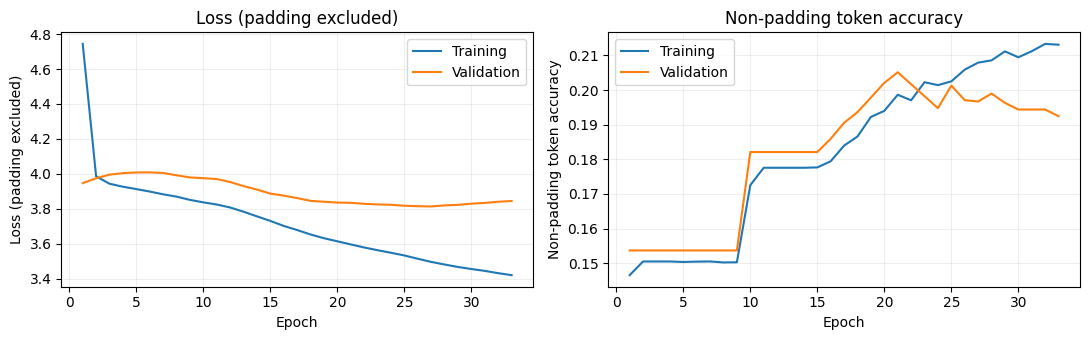

In [7]:
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
epochs = range(1,len(history.history['loss'])+1)
for ax, metric, title in zip(axes, ['loss','token_accuracy'], ['Loss (padding excluded)','Non-padding token accuracy']):
    ax.plot(epochs,history.history[metric],label='Training')
    ax.plot(epochs,history.history['val_'+metric],label='Validation')
    ax.set(xlabel='Epoch',ylabel=title,title=title)
    ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [8]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
test_metrics = translation_model.evaluate(dataset(x_test,y_test),verbose=0,return_dict=True)
# Predict in small batches to keep peak memory low.
prediction_ids = np.concatenate([
    np.argmax(translation_model(x_test[i:i+64],training=False).numpy(),axis=-1)
    for i in range(0,len(x_test),64)])
def decode(ids):
    words=[]
    for token in ids:
        word=target_tokenizer.index_word.get(int(token),'')
        if word == 'endseq': break
        if word: words.append(word)
    return ' '.join(words)
predictions=[decode(ids) for ids in prediction_ids]
# Preserve unseen reference words: do not replace the true references with <unk>.
references=[tf.keras.preprocessing.text.text_to_word_sequence(s)
            for s in test_pairs.french]
bleu=corpus_bleu([[r] for r in references],[s.split() for s in predictions],
    smoothing_function=SmoothingFunction().method1)
exact=np.mean([p.split()==r for p,r in zip(predictions,references)])
print(f'Test loss: {test_metrics["loss"]:.4f}')
print(f'Test non-padding token accuracy (includes end token): {test_metrics["token_accuracy"]:.4f}')
print(f'Test corpus BLEU-4 (smoothed, 0–100): {100*bleu:.2f}')
print(f'Test exact sentence match: {100*exact:.2f}%')
display(pd.DataFrame({'English':test_pairs.english.to_list()[:10],
    'Reference French':test_pairs.french.to_list()[:10],
    'Model prediction':predictions[:10]}))

Test loss: 3.8875
Test non-padding token accuracy (includes end token): 0.1999
Test corpus BLEU-4 (smoothed, 0–100): 0.17
Test exact sentence match: 0.00%


,English,Reference French,Model prediction
0,why don't you do that yourself?,pourquoi ne faites-vous pas cela vous-même ?,je ne pas pas de de
1,keep singing.,continue de chanter.,je tom
2,he is absent from school today.,il est absent de l'école aujourd'hui.,je ne pas de de
3,that was great advice.,ce furent d'excellents conseils.,je ne pas
4,where do i sleep?,où est-ce que je dors ?,je ne pas
5,tom doesn't keep his promises.,tom ne tient pas ses promesses.,je ne pas de de
6,i'm terrified.,je suis terrifié.,je est
7,tom's dog is well-trained.,le chien de tom est bien éduqué.,je ne pas de de de
8,i want to know why you're late.,je veux savoir pourquoi vous êtes en retard.,je ne pas pas de de de
9,my foot really hurts.,mon pied me fait vraiment mal.,je ne pas de


In [9]:
def normalize_text(text):
    return re.sub(r'\s+', ' ',unicodedata.normalize('NFKC',text).lower().replace('’', "'")).strip()

def translate_english(text):
    if not isinstance(text,str) or not text.strip():
        return '(Please enter a non-empty English sentence.)'
    ids=source_tokenizer.texts_to_sequences([normalize_text(text)])
    if not ids[0]: return '(No recognized word tokens.)'
    padded=pad_sequences(ids,maxlen=SOURCE_LENGTH,padding='post',truncating='post')
    result=decode(np.argmax(translation_model(padded,training=False).numpy(),axis=-1)[0])
    notes=[]
    if 1 in ids[0]: notes.append('contains unknown source words')
    if len(ids[0])>SOURCE_LENGTH: notes.append('input truncated to 7 tokens')
    return (result or '(empty prediction)') + (' ['+'; '.join(notes)+']' if notes else '')

for sentence in ['How are you?', 'I like this product.', 'The price is too high.', 'Thank you.', '']:
    print('English:',repr(sentence),'\nModel prediction:',translate_english(sentence),'\n')
assert prediction_ids.shape == y_test.shape
assert np.isfinite(list(test_metrics.values())).all()
assert 0 <= bleu <= 1
print('Checks passed: disjoint splits, sample integrity, prediction shapes, and finite metrics.')

English: 'How are you?' 
Model prediction: je est 

English: 'I like this product.' 
Model prediction: je est de 

English: 'The price is too high.' 
Model prediction: je ne pas 

English: 'Thank you.' 
Model prediction: je le 

English: '' 
Model prediction: (Please enter a non-empty English sentence.) 

Checks passed: disjoint splits, sample integrity, prediction shapes, and finite metrics.


### My interpretation and conclusion

In my saved run, validation loss selected epoch 27. My test token accuracy was 19.99%, smoothed BLEU-4 was 0.17/100, and exact sentence match was 0%. These low scores and examples such as "je est" show that the workflow runs, but the model has not learned reliable translation. The training/validation gap also indicates overfitting. I report these results as measured rather than replacing predictions with reference translations.
I use held-out BLEU and example predictions to judge translation quality, rather than treating token accuracy as sentence accuracy. Even after padding is excluded, common words and the end token can make token accuracy look better than actual translations. BLEU compares my predictions with one reference per sentence, so it may also penalize valid alternative translations.

My small fixed-context LSTM has limited vocabulary and can produce incomplete or incorrect French. The dataset contains general sentences rather than an e-commerce training corpus. The shopping examples above are model predictions, not verified translations, and I would not deploy this model for product listings or customer reviews.

For a stronger solution, I would use more bilingual data, add product and review examples, use subword tokenization and an attention-based or pretrained translation model, and check names, prices, negation, and customer-facing terminology with French speakers. I would also evaluate on a separate e-commerce test set. In this lab I demonstrate the complete preprocessing, training, evaluation, and inference workflow.